# Plant Disease Detector

A simple image classifier that looks at a photo of a leaf and says which plant it is and whether it is healthy or diseased.

**How it works, in 5 steps**

1. Look at the dataset (38 classes of leaf photos).
2. Turn every image into a list of numbers (shrink it to 48x48 pixels and flatten it).
3. Split the data into a training set and a test set.
4. Train a small neural network (an MLP from scikit-learn) on the training set.
5. Check how well it does on the test set, then save the model so the app can use it.

In [1]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import joblib

DATASET_DIR = "dataset"   # one sub-folder per class
IMG_SIZE = 48             # every image is shrunk to 48x48 pixels (64 needs more than 8 GB of RAM)

## Step 1: Look at the dataset

Each folder inside `dataset/` is one class. The folder name is the label, for example `Tomato_Early_blight`.

In [2]:
class_names = sorted(os.listdir(DATASET_DIR))
counts = {name: len(os.listdir(os.path.join(DATASET_DIR, name))) for name in class_names}

print(f"{len(class_names)} classes, {sum(counts.values())} images in total\n")
for name, n in counts.items():
    print(f"{n:6d}  {name}")

38 classes, 54305 images in total

   630  Apple_Apple_scab
   621  Apple_Black_rot
   275  Apple_Cedar_apple_rust
  1645  Apple_healthy
  1502  Blueberry_healthy
  1052  Cherry_including_sour_Powdery_mildew
   854  Cherry_including_sour_healthy
   513  Corn_maize_Cercospora_leaf_spot_Gray_leaf_spot
  1192  Corn_maize_Common_rust
   985  Corn_maize_Northern_Leaf_Blight
  1162  Corn_maize_healthy
  1180  Grape_Black_rot
  1383  Grape_Esca_Black_Measles
  1076  Grape_Leaf_blight_Isariopsis_Leaf_Spot
   423  Grape_healthy
  5507  Orange_Haunglongbing_Citrus_greening
  2297  Peach_Bacterial_spot
   360  Peach_healthy
   997  Pepper_bell_Bacterial_spot
  1478  Pepper_bell_healthy
  1000  Potato_Early_blight
  1000  Potato_Late_blight
   152  Potato_healthy
   371  Raspberry_healthy
  5090  Soybean_healthy
  1835  Squash_Powdery_mildew
  1109  Strawberry_Leaf_scorch
   456  Strawberry_healthy
  2127  Tomato_Bacterial_spot
  1000  Tomato_Early_blight
  1909  Tomato_Late_blight
   952  Tomato_

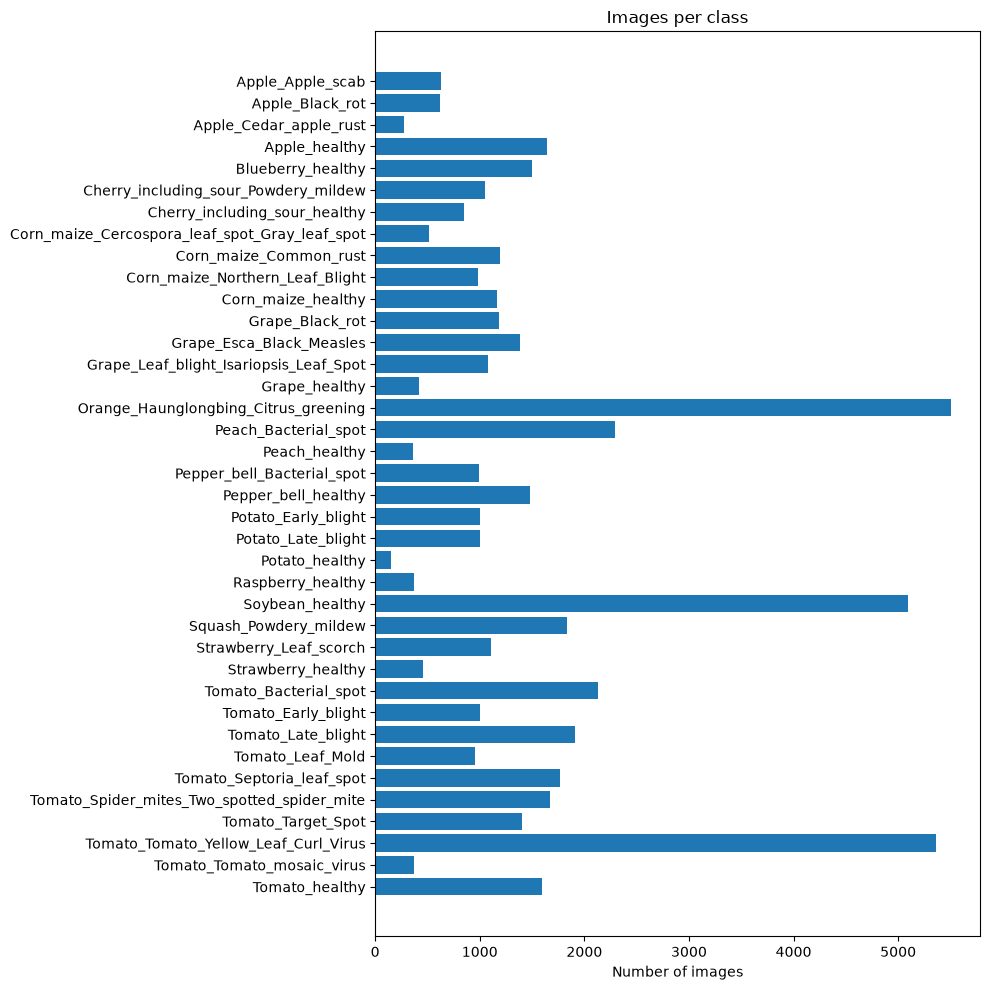

In [3]:
plt.figure(figsize=(10, 10))
plt.barh(list(counts.keys()), list(counts.values()))
plt.xlabel("Number of images")
plt.title("Images per class")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

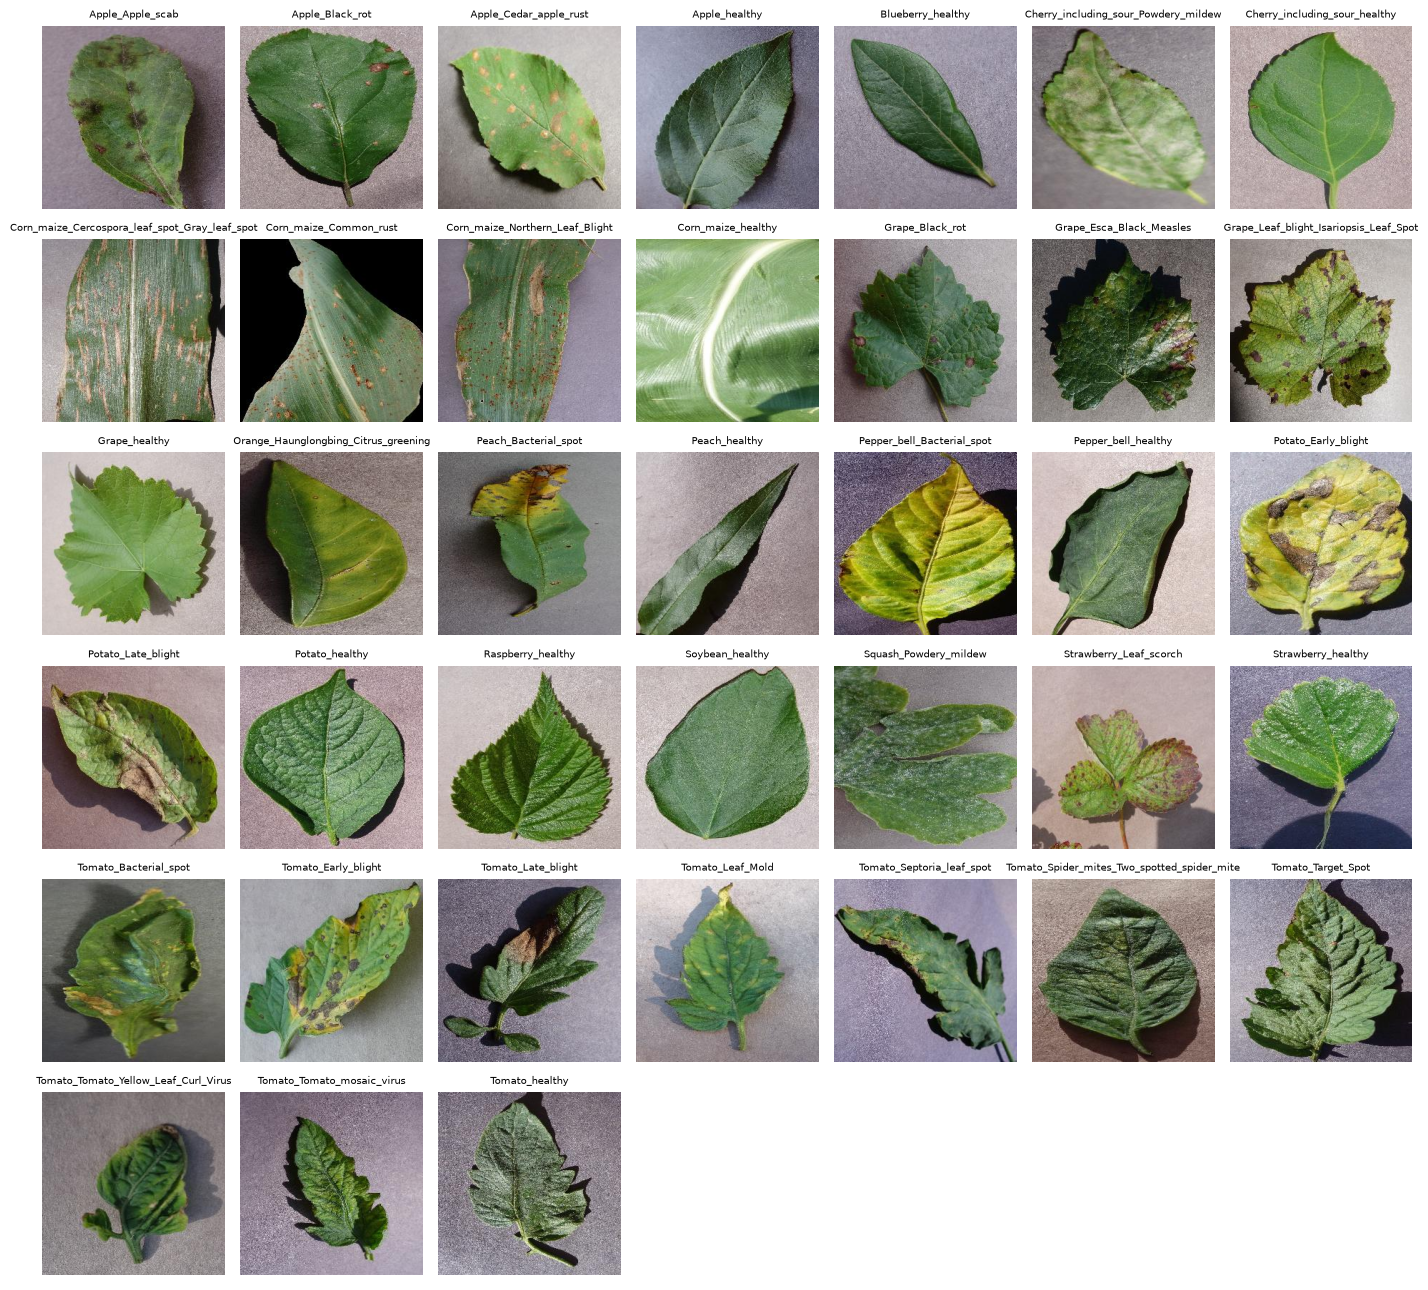

In [4]:
# One example image from every class
fig, axes = plt.subplots(6, 7, figsize=(14, 13))
for ax, name in zip(axes.flat, class_names):
    first_file = os.listdir(os.path.join(DATASET_DIR, name))[0]
    ax.imshow(Image.open(os.path.join(DATASET_DIR, name, first_file)))
    ax.set_title(name, fontsize=7)
    ax.axis("off")
for ax in axes.flat[len(class_names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 2: Turn images into numbers

A computer cannot learn from a picture directly, only from numbers. So for every image we:

- open it and shrink it to 48x48 pixels,
- read the red, green and blue value of every pixel (48 x 48 x 3 = 6912 numbers),
- flatten those numbers into one long row.

`X` ends up as a big table with one row per image and 6912 columns. `y` holds the class number for each row.

This takes a few minutes because there are about 54,000 images.

In [5]:
def image_to_row(path):
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(img).flatten()

X = []
y = []
start = time.time()
for label, name in enumerate(class_names):
    folder = os.path.join(DATASET_DIR, name)
    for file in os.listdir(folder):
        X.append(image_to_row(os.path.join(folder, file)))
        y.append(label)
    print(f"loaded {name}")

X = np.array(X, dtype=np.float32) / 255.0   # scale pixel values from 0-255 to 0-1
y = np.array(y)

print(f"\nDone in {time.time() - start:.0f} seconds")
print("X shape:", X.shape, " (images, numbers per image)")
print("y shape:", y.shape)

loaded Apple_Apple_scab


loaded Apple_Black_rot
loaded Apple_Cedar_apple_rust


loaded Apple_healthy


loaded Blueberry_healthy


loaded Cherry_including_sour_Powdery_mildew


...

loaded Tomato_Target_Spot


loaded Tomato_Tomato_Yellow_Leaf_Curl_Virus


loaded Tomato_Tomato_mosaic_virus


loaded Tomato_healthy



Done in 32 seconds
X shape: (54305, 6912)  (images, numbers per image)
y shape: (54305,)


## Step 3: Split into training and test sets

We keep 20% of the images hidden from the model during training. Afterwards we test on them to see if the model really learned or just memorised.

`stratify=y` makes sure every class is split in the same 80/20 ratio.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("training images:", len(X_train))
print("test images:    ", len(X_test))

training images: 43444
test images:     10861


## Step 4: Train the model

We use an **MLP (Multi-Layer Perceptron)**, the simplest kind of neural network:

- **input layer**: 6912 numbers (the pixels)
- **hidden layer**: 256 neurons that learn useful patterns
- **output layer**: 38 numbers, one score per class; the highest score is the prediction

`max_iter=100` means the model looks at the whole training set up to 100 times. `verbose=True` prints the loss after every pass; it should go down.

In [7]:
model = MLPClassifier(hidden_layer_sizes=(256,), max_iter=100, random_state=42, verbose=True)

start = time.time()
model.fit(X_train, y_train)
print(f"\nTraining took {time.time() - start:.0f} seconds")

Iteration 1, loss = 2.71968914


Iteration 2, loss = 1.84752373


Iteration 3, loss = 1.59759406


Iteration 4, loss = 1.43861482


Iteration 5, loss = 1.33436111


...

Iteration 97, loss = 0.46586095


Iteration 98, loss = 0.46463087


Iteration 99, loss = 0.46887465


Iteration 100, loss = 0.46314077

Training took 221 seconds


/Users/uzair/Dev/anoosh-project/plant-disease-detector/.venv/lib/python3.11/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


## Step 5: Evaluate

Accuracy = fraction of images the model labels correctly. Training accuracy is always higher; test accuracy is the honest number.

In [8]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

print(f"Training accuracy: {accuracy_score(y_train, train_pred):.1%}")
print(f"Test accuracy:     {accuracy_score(y_test, test_pred):.1%}")

Training accuracy: 86.5%
Test accuracy:     76.5%


In [9]:
# Precision / recall for every class
print(classification_report(y_test, test_pred, target_names=class_names))

                                                precision    recall  f1-score   support

                              Apple_Apple_scab       0.77      0.56      0.65       126
                               Apple_Black_rot       0.77      0.65      0.71       124
                        Apple_Cedar_apple_rust       0.35      0.40      0.38        55
                                 Apple_healthy       0.68      0.70      0.69       329
                             Blueberry_healthy       0.69      0.80      0.74       300
          Cherry_including_sour_Powdery_mildew       0.87      0.59      0.70       210
                 Cherry_including_sour_healthy       0.74      0.77      0.75       171
Corn_maize_Cercospora_leaf_spot_Gray_leaf_spot       0.59      0.32      0.42       103
                        Corn_maize_Common_rust       0.99      0.96      0.97       239
               Corn_maize_Northern_Leaf_Blight       0.63      0.78      0.70       197
                            Cor

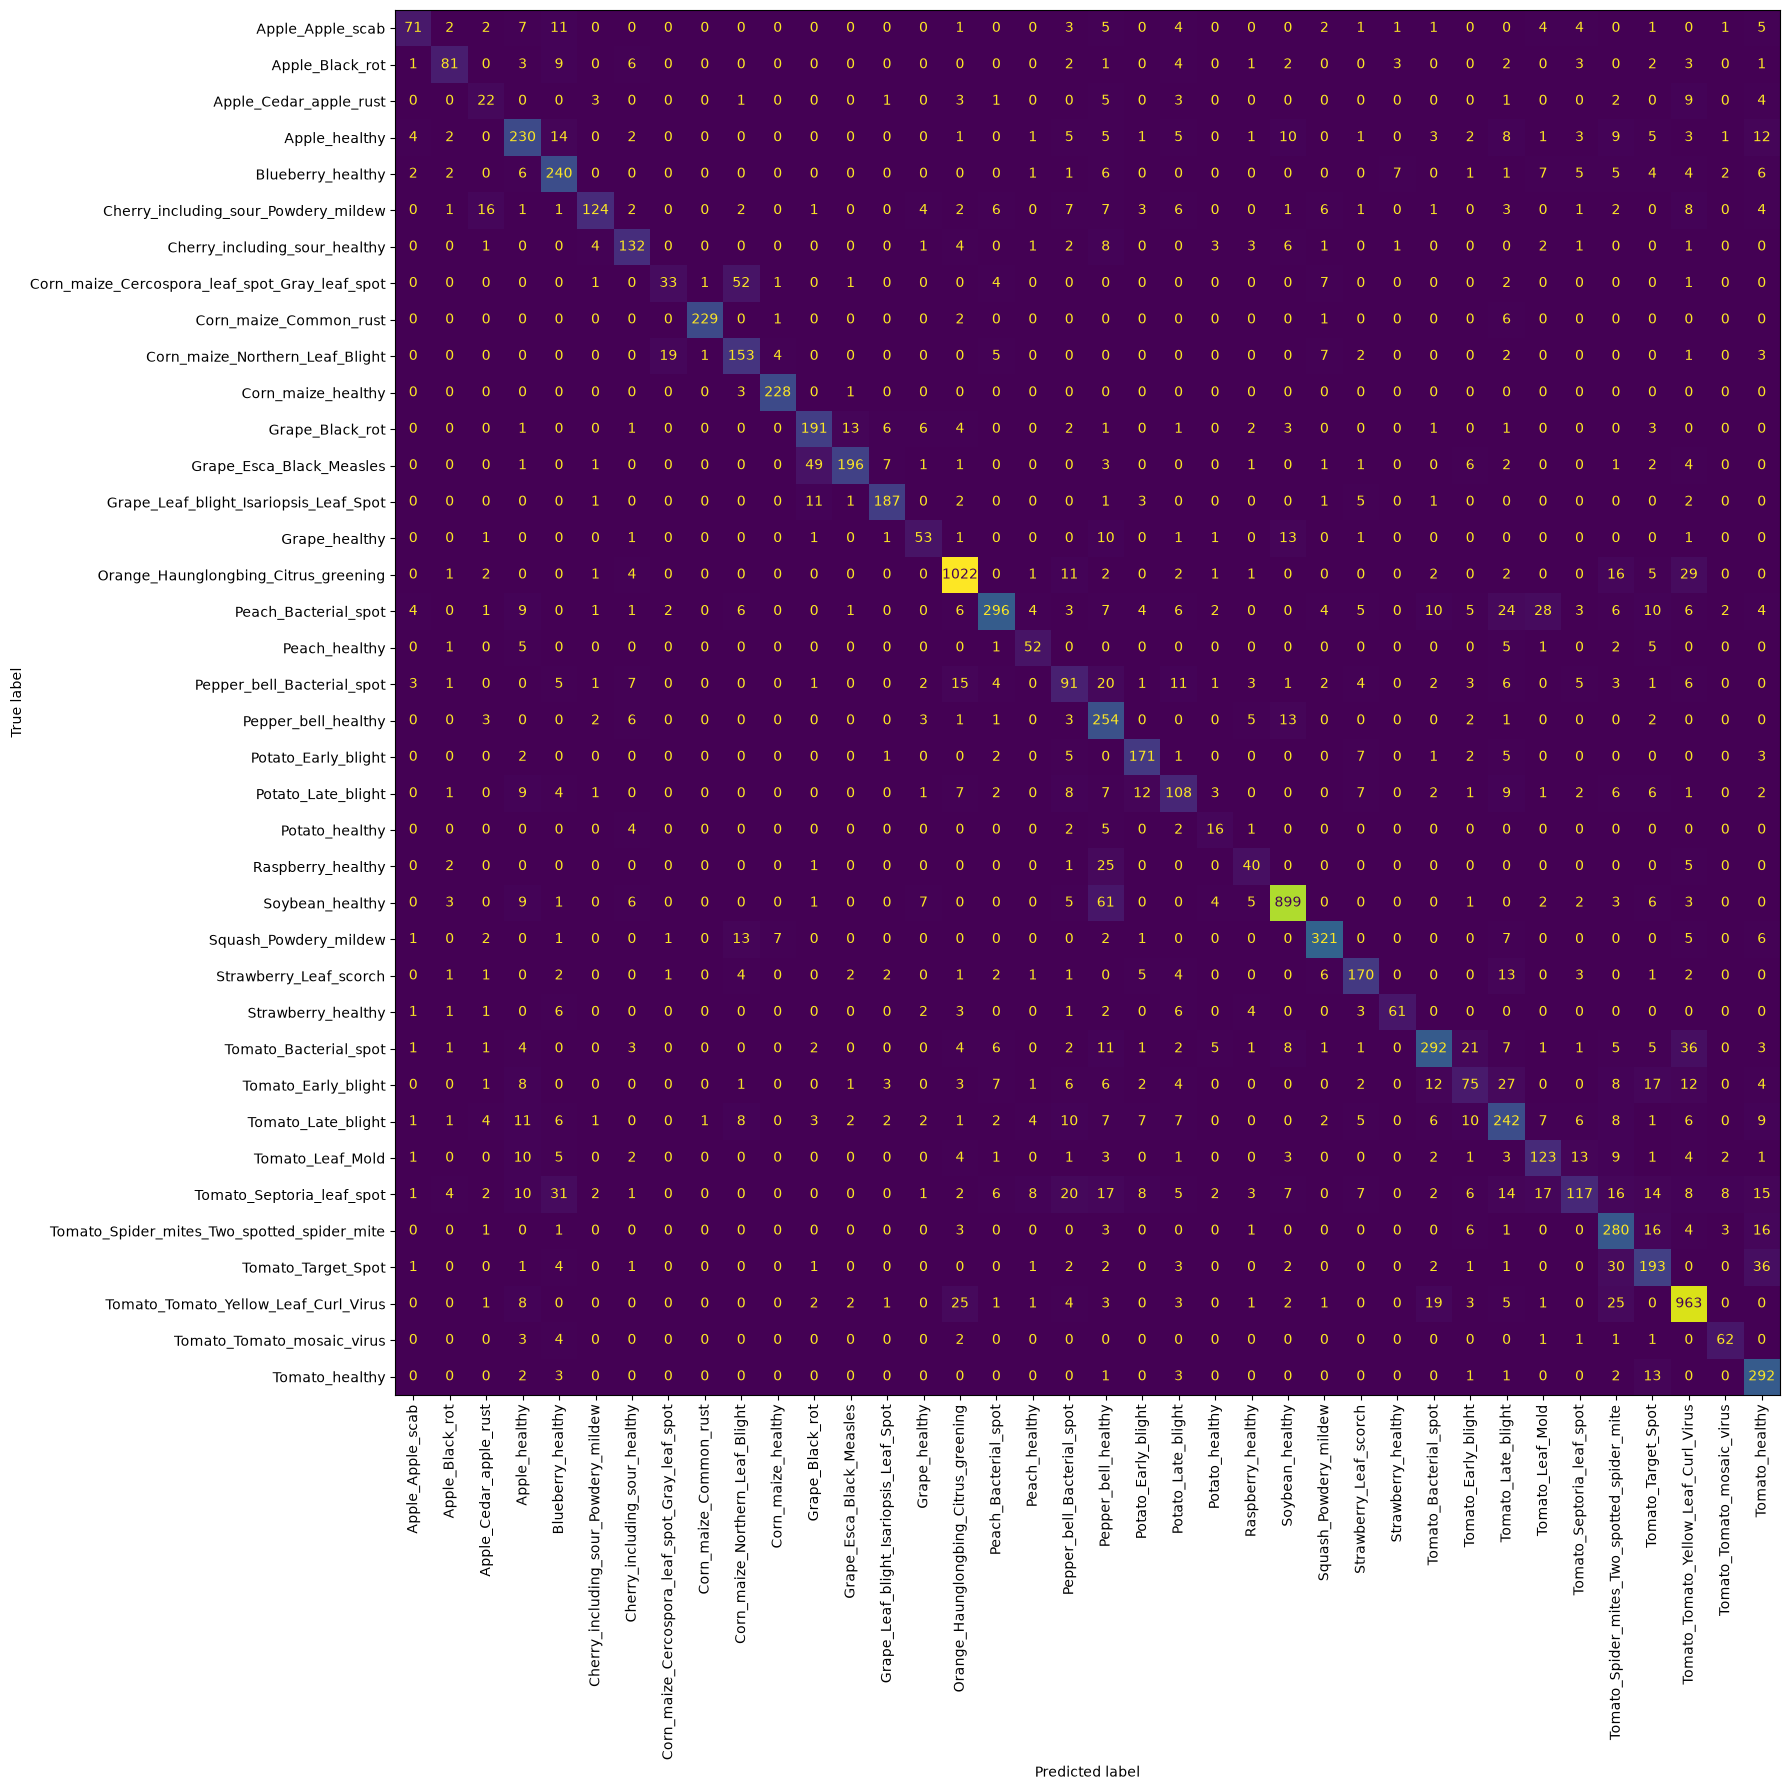

In [10]:
# Confusion matrix: rows are the true class, columns are what the model predicted.
# A perfect model has everything on the diagonal.
fig, ax = plt.subplots(figsize=(18, 18))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=class_names, ax=ax, xticks_rotation="vertical", colorbar=False
)
plt.tight_layout()
plt.show()

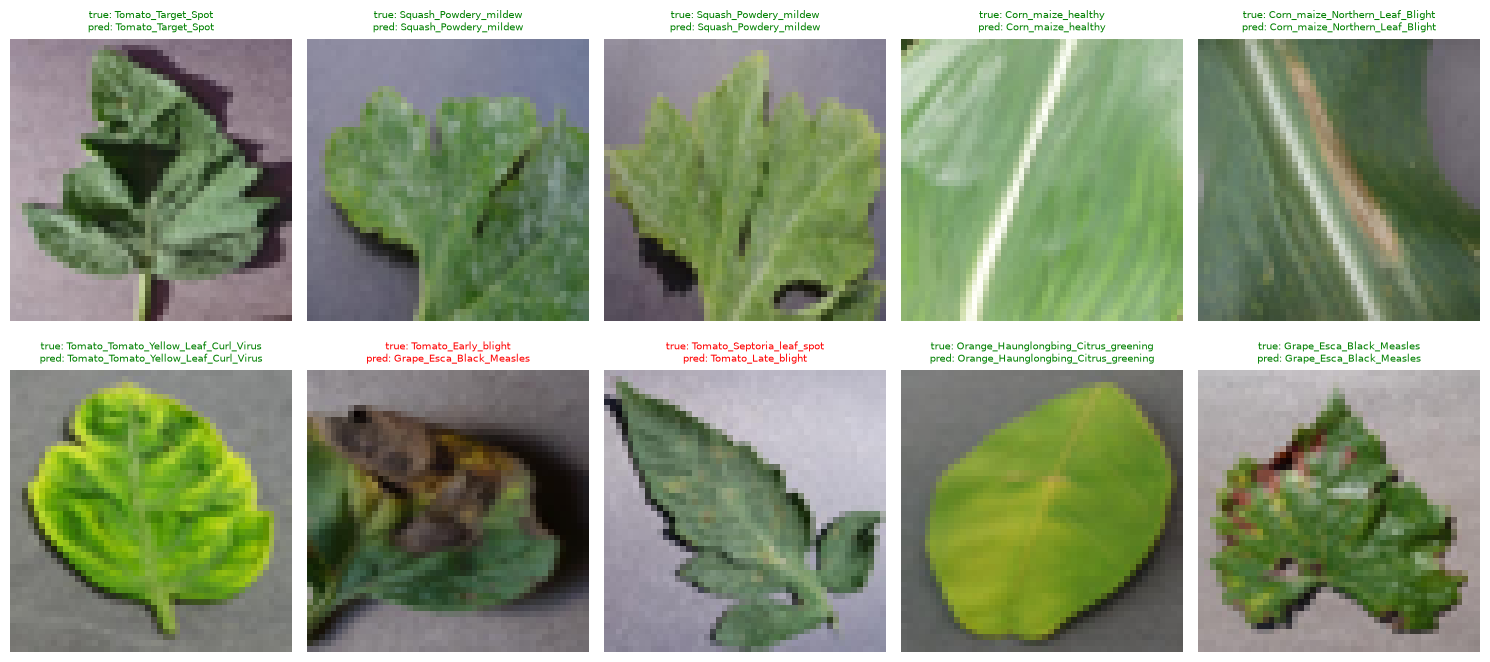

In [11]:
# A few test images with the true label and the model's guess
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for ax, i in zip(axes.flat, np.random.choice(len(X_test), 10, replace=False)):
    ax.imshow(X_test[i].reshape(IMG_SIZE, IMG_SIZE, 3))
    correct = y_test[i] == test_pred[i]
    ax.set_title(f"true: {class_names[y_test[i]]}\npred: {class_names[test_pred[i]]}",
                 fontsize=7, color="green" if correct else "red")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 6: Save the model

The Streamlit app loads this file and uses the exact same `image_to_row` steps on the photo it receives.

In [12]:
joblib.dump({"model": model, "class_names": class_names, "img_size": IMG_SIZE}, "model.joblib")
print(f"saved model.joblib ({os.path.getsize('model.joblib') / 1e6:.1f} MB)")

saved model.joblib (28.5 MB)


In [13]:
# Quick check: predict one image from disk, the same way the app will
def predict(path):
    row = image_to_row(path).astype(np.float32) / 255.0
    probs = model.predict_proba([row])[0]
    best = probs.argmax()
    return class_names[best], probs[best]

example = os.path.join(DATASET_DIR, "Tomato_healthy", os.listdir(os.path.join(DATASET_DIR, "Tomato_healthy"))[0])
label, confidence = predict(example)
print(f"{example}\n-> {label} ({confidence:.0%} confident)")

dataset/Tomato_healthy/8ad09f74_a565_413a_bcf5_21cf58a4db3a_RS_HL_0173.jpg
-> Tomato_healthy (97% confident)
